### Can you predict the party from the speeches? Does it change over time? 

In [32]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
from pathlib import Path
plt.rcParams['savefig.dpi'] = 300

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, mean_squared_error)
from sklearn.model_selection import (train_test_split)

from paths import RAW, DERIVED, FIGURES

#### Data Pipeline: 

1. Import data from each congress. Use a small sample, such as 2000 speeches, with only speeches from D and R and > 100 words. 

2. Split into training and test data. Fit a logistic regression. Keep track of the test accuracy for each congress, and then graph. 

In [33]:
con = duckdb.connect(str(DERIVED / 'congress.duckdb'))

In [34]:
sample_size = 1000

#takes the ids into a df
keys = con.sql(f'''

SELECT speech_id, party_group, party, congress
FROM everything_but_speeches
WHERE party IN ('D', 'R') AND word_count >= 100

''').df()

#take a random smaple of the dataframe, using random state for reproducibility. 2000 per congress. 
random_sample = (
    keys.sample(frac = 1, random_state = 42)
        .groupby(['congress','party_group'])
        .head(sample_size)
    )

#join back into the text using the randomly generated IDs to get the reduced speeches dataframe. 
# from random_sample (a dataframe) and speeches, a duck db
sample = con.sql('''
SELECT speech_id, congress, party_group, text
FROM speeches
JOIN random_sample USING (speech_id)
''').df()

print(sample.shape)
sample.head(4)

(138000, 4)


,speech_id,congress,party_group,text
0,430005014,43,Republican,Mr. speaker. if the qIncstiol before the House...
1,430005019,43,Republican,I shall. when the proper time arrives. tale th...
2,430005109,43,Republican,The bill has not yet been printed. for this te...
3,430005120,43,Democrat,Mr. Speaker. I had not intended to say anythin...


In [35]:
# now a loop that fits tfidf and logit, and takes accuracy. 

congresses = list(range(43, 112))
results = []

for congress in congresses:
    print(congress)
    first_id = congress * 10000000
    last_id = (congress +1) * 10000000 - 1


    df = sample.loc[sample['congress'] == congress]

    X_train, X_test, y_train, y_test = train_test_split(
        df['text'], df['party_group'],
        test_size=0.25, stratify=df['party_group'], random_state=42) #each split has the same fraction of party. random state reproducible. 25% test. 

    #generate stop words - want to get rid of speaker that could be too partisan in between them. 

    speakers_from_congress = con.sql(f'''
    SELECT DISTINCT lastname
    FROM everything_but_speeches
    WHERE speech_id BETWEEN {first_id} AND {last_id}
    ''').df()

    speakers = set(speakers_from_congress['lastname'].dropna().str.lower().str.findall(r'\b\w\w+\b').explode().dropna())

    stops = list(ENGLISH_STOP_WORDS | speakers)


    tfidf_vec = TfidfVectorizer(min_df=5, max_df = 0.5, stop_words=stops)

    tfidf_train = tfidf_vec.fit_transform(X_train)
    tfidf_test = tfidf_vec.transform(X_test)
    #logit because outcome is binary 
    logit = LogisticRegression(max_iter=2000)
    logit.fit(tfidf_train, y_train)


    score = logit.score(tfidf_test, y_test)
    predict = logit.predict(tfidf_test)

    report = classification_report(y_test, predict, output_dict=True)


    results.append({
        'congress': congress,
        'accuracy': score,
        'rep_prec': report['Republican']['precision'],
        'rep_recall': report['Republican']['recall'],
        'year': (1789 + 2* (congress - 1))
    })

modelscores = pd.DataFrame(results)

modelscores.to_csv(DERIVED / 'logit_scores.csv', index = False)

43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111


In [36]:
con.close()

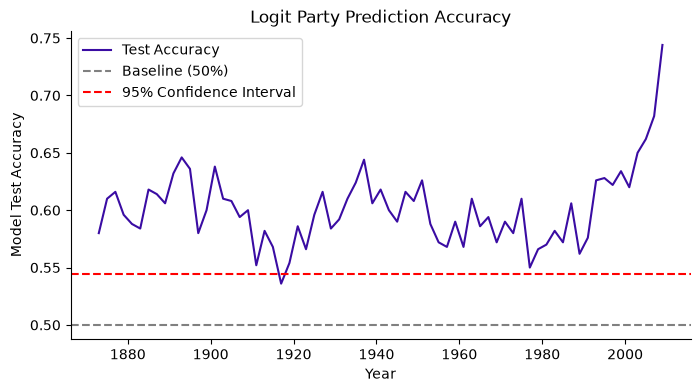

In [37]:
res = pd.read_csv(DERIVED / 'logit_scores.csv')

modelfigs = Path(FIGURES / 'modelfigs')
modelfigs.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data=res,
        x='year',
        y= 'accuracy',
        color = '#3A0CA3',
        ax=ax,
        label = 'Test Accuracy'
    )
ax.set(
        xlabel = 'Year', 
        ylabel = 'Model Test Accuracy',
        title =  'Logit Party Prediction Accuracy'
    )
ax.axhline(0.5, linestyle='--', color='gray', label='Baseline (50%)')
ax.axhline(0.544, linestyle='--', color='red', label='95% Confidence Interval')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.savefig(FIGURES / modelfigs / 'logit_accuracy.png', bbox_inches='tight')


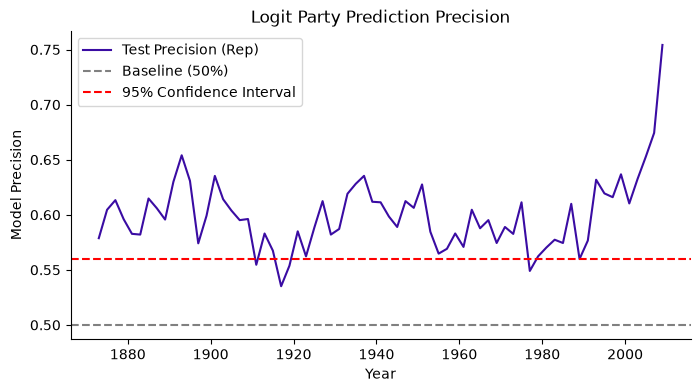

In [38]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data=res,
        x='year',
        y= 'rep_prec',
        color = '#3A0CA3',
        ax=ax,
        label = 'Test Precision (Rep)'
    )
ax.set(
        xlabel = 'Year', 
        ylabel = 'Model Precision',
        title =  'Logit Party Prediction Precision'
    )
ax.axhline(0.5, linestyle='--', color='gray', label='Baseline (50%)')
ax.axhline(0.56, linestyle='--', color='red', label='95% Confidence Interval')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.savefig(FIGURES / modelfigs / 'logit_precision.png', bbox_inches='tight')


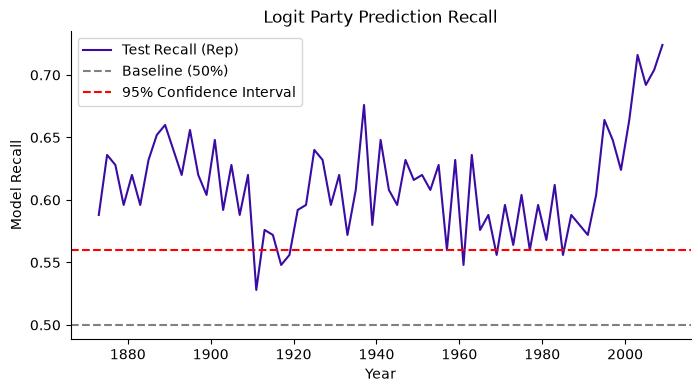

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.lineplot(
        data=res,
        x='year',
        y= 'rep_recall',
        color = '#3A0CA3',
        ax=ax,
        label = 'Test Recall (Rep)'
    )
ax.set(
        xlabel = 'Year', 
        ylabel = 'Model Recall',
        title =  'Logit Party Prediction Recall'
    )
ax.axhline(0.5, linestyle='--', color='gray', label='Baseline (50%)')
ax.axhline(0.56, linestyle='--', color='red', label='95% Confidence Interval')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)

fig.savefig(FIGURES / modelfigs / 'logit_recall.png', bbox_inches='tight')
